# Credit Card Default Prediction (logistic regression)

A beginner-friendly **binary-classification** walkthrough, built from the
churn template and applied to a new dataset: predicting whether a credit-card
client will **default** next month.

Every section explains **what** we're doing, **why**, and **what the output means**.

### Dataset

- **Default of Credit Card Clients** — UCI Machine Learning Repository
- <https://archive.ics.uci.edu/ml/datasets/default+of+credit+card+clients>
- 30,000 clients, 23 features (credit limit, demographics, past payment history,
  bill amounts, payment amounts), target = default next month (yes/no).

> **Where the data comes from.** UCI ships this as an `.xls` file. It has been
> converted once to `data/credit_card_default.csv` so the notebook can read a plain
> CSV (see the note in 3.2). The columns were left exactly as UCI defines them.

### Why logistic regression?

Predicting default is a **yes/no** outcome -> a classifier. Logistic regression is
the simplest one: a linear model whose output is squashed into a probability.
It's a good, interpretable baseline.

---

### The big picture (read this first)

1. **Load data** — a table of clients with features and a known answer.
2. **Split** — keep some data hidden so we can test honestly.
3. **Explore** — learn which columns look useful.
4. **Preprocess** — turn categories into numbers the model understands.
5. **Train** — let the model find the relationship between features and the answer.
6. **Evaluate** — measure how good it is on data it has never seen.
7. **Interpret & analyze errors** — understand *why* it's right or wrong.

### Tiny glossary

- **Feature (X)** — an input column (e.g. `limit_bal`, `age`).
- **Target / label (y)** — what we predict (here: default, 0 or 1).
- **Binary classification** — predicting one of two classes.
- **Model** — a function that maps features to a prediction.
- **Training** — fitting the model's parameters to data.
- **Leakage** — accidentally letting the model see the answer.
- **Pipeline** — a bundle of preprocessing steps + model that runs together.


## 3.1 The template knobs (what changes per dataset)

This notebook is the churn template re-pointed at a new dataset. Only a few
settings differ:

| Knob | Churn notebook | This notebook |
|---|---|---|
| `DATA_PATH` | `../data/telco.csv` | `../data/credit_card_default.csv` |
| `TARGET` | `churn` | `default_payment_next_month` |
| `POSITIVE_LABEL` | `'yes'` | `1` |
| feature lists | telco columns | credit-card columns (see 3.4) |

Everything else — the split, `ColumnTransformer` + `Pipeline`, coefficients,
metrics, and error analysis — is the same code.


## 3.2 Load and clean the data

**Goal:** a clean table where column names are consistent, numbers are numbers, and
the target is 0/1.

**Packages:** `pandas`, `numpy`, `matplotlib`.

> **Data prep note.** The original UCI file is `.xls` with a title row above the
> header. We converted it once to `data/credit_card_default.csv` using:
> ```python
> pd.read_excel('default of credit card clients.xls', header=1).to_csv('credit_card_default.csv', index=False)
> ```
> The notebook itself only needs the CSV.


In [1]:
# Import the libraries we'll use throughout.
import pandas as pd                       # tables / data manipulation
import numpy as np                        # numbers and arrays
import matplotlib.pyplot as plt           # plotting


/Users/raymondcancino/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/w5/07555mrj4b92zd89byxnxjnr0000gn/T/matplotlib-tx4qpe2a because there was an issue with the default path (/Users/raymondcancino/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/raymondcancino/.cache/fontconfig
	/Users/raymondcancino/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/raymondcancino/.cache/fontconfig
	/Users/raymondcancino/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/raymondcancino/.cache/fontconfig
	/Users/raymondcancino/.fontconfig



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/raymondcancino/.cache/fontconfig
	/Users/raymondcancino/.fontconfig


Matplotlib is building the font cache; this may take a moment.


In [2]:
# --- TEMPLATE KNOBS (change these for a new dataset) ---
DATA_PATH = '../data/credit_card_default.csv'      # where the CSV lives
TARGET = 'default_payment_next_month'              # column we want to predict
POSITIVE_LABEL = 1                                 # value of TARGET that means "yes"


In [3]:
# Read the CSV into a table (DataFrame)
df = pd.read_csv(DATA_PATH)

# First 5 rows
df.head()


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [4]:
df.head().T

,0,1,2,3,4
ID,1,2,3,4,5
LIMIT_BAL,20000,120000,90000,50000,50000
SEX,2,2,2,2,1
EDUCATION,2,2,2,2,2
MARRIAGE,1,2,2,1,1
AGE,24,26,34,37,57
PAY_0,2,-1,0,0,-1
PAY_2,2,2,0,0,0
PAY_3,-1,0,0,0,-1
PAY_4,-1,0,0,0,0


### Clean column names

UCI names are mixed-case with spaces (`LIMIT_BAL`, `default payment next month`).
We lowercase and replace spaces with underscores so references never break.


In [5]:
# Column names: lowercase + spaces -> underscores
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.columns.tolist()


['id',
 'limit_bal',
 'sex',
 'education',
 'marriage',
 'age',
 'pay_0',
 'pay_2',
 'pay_3',
 'pay_4',
 'pay_5',
 'pay_6',
 'bill_amt1',
 'bill_amt2',
 'bill_amt3',
 'bill_amt4',
 'bill_amt5',
 'bill_amt6',
 'pay_amt1',
 'pay_amt2',
 'pay_amt3',
 'pay_amt4',
 'pay_amt5',
 'pay_amt6',
 'default_payment_next_month']

In [6]:
df.head().T

,0,1,2,3,4
id,1,2,3,4,5
limit_bal,20000,120000,90000,50000,50000
sex,2,2,2,2,1
education,2,2,2,2,2
marriage,1,2,2,1,1
age,24,26,34,37,57
pay_0,2,-1,0,0,-1
pay_2,2,2,0,0,0
pay_3,-1,0,0,0,-1
pay_4,-1,0,0,0,0


### Encode the target as 0/1

The target column is already 0/1 in this dataset, but we write the step explicitly
(and generalize it with `POSITIVE_LABEL`) so the notebook still works if a target
arrives as text.


In [7]:
# Turn the target into 0/1: 1 where it equals POSITIVE_LABEL, else 0
df[TARGET] = (df[TARGET] == POSITIVE_LABEL).astype(int)

# Confirm we have both classes (0 = repaid, 1 = default)
df[TARGET].value_counts()


default_payment_next_month
0    23364
1     6636
Name: count, dtype: int64

## 3.3 Split into train / validation / test

**Why split?** If we score the model on the data it learned from, it looks better
than it is. So we hold data out.

| Set | Size | Purpose |
|---|---|---|
| **train** | 60% | the model learns from this |
| **validation** | 20% | used to *make choices* (check the model) |
| **test** | 20% | used **once at the end** for an honest score |

Analogy: train = homework, validation = practice quizzes, test = the final exam.

We get 60/20/20 by calling `train_test_split` twice: carve off 20% for test, then
25% of the remaining 80% for validation.

**Package:** `sklearn.model_selection.train_test_split`.


In [8]:
from sklearn.model_selection import train_test_split

# 80% train+val, 20% test (random_state=1 -> reproducible split)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

# 25% of the remaining 80% -> validation (20% overall); train is the last 60%
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

len(df_train), len(df_val), len(df_test)


(18000, 6000, 6000)

### Separate features (X) from the target (y)

We copy `y` out **before** dropping the target from X. Leaving the answer inside X
would let the model "cheat" — that mistake is called **leakage**.

We also **drop the `id` column**: it's just a row identifier with no predictive
meaning. (We drop it only from the feature frames, not from the whole dataset.)


In [9]:
# Clean 0..n-1 indexes
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

# y = target values as numpy arrays
y_train = df_train[TARGET].values
y_val = df_val[TARGET].values
y_test = df_test[TARGET].values
y_full_train = df_full_train[TARGET].values

# X = features only: drop the target AND the id column
df_train = df_train.drop(columns=[TARGET, 'id'])
df_val = df_val.drop(columns=[TARGET, 'id'])
df_test = df_test.drop(columns=[TARGET, 'id'])


## 3.4 Summarize the data

Before modeling, look at the data: size, types, missing values, duplicates, class
balance, and feature ranges. We profile **train + validation** only — never test.

**Package:** `pandas`.


### The variables (as defined by the dataset authors)

The original UCI study describes the data like this — worth reading before we
choose which columns are numeric vs categorical:

> This research employed a binary variable, default payment (Yes = 1, No = 0), as
> the response variable. This study reviewed the literature and used the following
> 23 variables as explanatory variables:
>
> **X1: Amount of the given credit (NT dollar)** — includes both the individual
> consumer credit and his/her family (supplementary) credit.
>
> **X2: Gender** (1 = male; 2 = female).
>
> **X3: Education** (1 = graduate school; 2 = university; 3 = high school; 4 = others).
>
> **X4: Marital status** (1 = married; 2 = single; 3 = others).
>
> **X5: Age** (year).
>
> **X6 - X11: History of past payment.** We tracked the past monthly payment records
> (from April to September, 2005) as follows: X6 = the repayment status in September,
> 2005; X7 = the repayment status in August, 2005; ...; X11 = the repayment status in
> April, 2005. The measurement scale for the repayment status is: -1 = pay duly;
> 1 = payment delay for one month; 2 = payment delay for two months; ...; 8 = payment
> delay for eight months; 9 = payment delay for nine months and above.
>
> **X12 - X17: Amount of bill statement (NT dollar).** X12 = amount of bill statement
> in September, 2005; X13 = amount of bill statement in August, 2005; ...; X17 =
> amount of bill statement in April, 2005.
>
> **X18 - X23: Amount of previous payment (NT dollar).** X18 = amount paid in
> September, 2005; X19 = amount paid in August, 2005; ...; X23 = amount paid in
> April, 2005.

**Mapping these to the CSV columns we load:**

| UCI label | CSV column | Meaning | Treat as |
|---|---|---|---|
| response | `default_payment_next_month` | defaulted next month (1 = yes) | **target** |
| X1 | `limit_bal` | credit limit (NT$) | numeric |
| X2 | `sex` | 1 = male, 2 = female | **categorical** |
| X3 | `education` | 1 = grad, 2 = university, 3 = high school, 4 = others | **categorical** |
| X4 | `marriage` | 1 = married, 2 = single, 3 = others | **categorical** |
| X5 | `age` | age (years) | numeric |
| X6-X11 | `pay_0, pay_2 ... pay_6` | repayment status (Apr-Sep 2005), levels -1...9 | **categorical** |
| X12-X17 | `bill_amt1 ... bill_amt6` | bill statement amount (NT$) | numeric |
| X18-X23 | `pay_amt1 ... pay_amt6` | previous payment amount (NT$) | numeric |

> **Two notes on the mapping**
> - **Pay status (`pay_*`).** The dataset's most recent month (September, X6) is
>   stored in the CSV under the name `pay_0`; the rest are `pay_2`...`pay_6`. Despite
>   the numeric codes (-1, 1, 2, ... 9), these are **ordered categories** (levels of
>   lateness), so we one-hot encode them rather than feed them as raw numbers.
> - **The scale definition says "-1 = pay duly; 1..9 = months delayed".** Values of
>   `0` (and other codes) also appear in practice; one-hot encoding handles every code
>   as its own category automatically.


### The feature-list knobs (important for this dataset)

This is where the new dataset needs thought. Looking at the raw columns:

- **`limit_bal`, `age`** — genuinely numeric (money, years).
- **`bill_amt1..6`, `pay_amt1..6`** — numeric (amounts in NTD).
- **`sex`, `education`, `marriage`** — these are stored as **integers** but are
  really **categories** (codes: 1=female/2=male, education levels, etc.). Feeding
  them to the model as raw numbers would imply a false ordering, so we treat them
  as **categorical** and one-hot encode them.
- **`pay_0, pay_2 .. pay_6`** — repayment status in the last months, e.g. -1 = paid
  on time, 1 = 1 month late, etc. These are **categories / levels**, not quantities,
  so we treat them as categorical too.

> **Note:** UCI defines the first repayment-status column as `PAY_0` (most recent).
> We treat all six `pay_*` columns the same way.


In [10]:
# --- TEMPLATE KNOBS: your feature lists ---
# Numeric: amounts and age (real quantities)
numerical = ['limit_bal', 'age'] + \
            [f'bill_amt{i}' for i in range(1, 7)] + \
            [f'pay_amt{i}'  for i in range(1, 7)]

# Categorical: coded flags/levels (one-hot encoded, NOT used as numbers)
categorical = ['sex', 'education', 'marriage'] + ['pay_0', 'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6']

print('numeric features   :', len(numerical))
print('categorical features:', len(categorical))


numeric features   : 14
categorical features: 9


In [11]:
# Shape, dtypes, non-null counts
df_full_train.info()


<class 'pandas.DataFrame'>
RangeIndex: 24000 entries, 0 to 23999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   id                          24000 non-null  int64
 1   limit_bal                   24000 non-null  int64
 2   sex                         24000 non-null  int64
 3   education                   24000 non-null  int64
 4   marriage                    24000 non-null  int64
 5   age                         24000 non-null  int64
 6   pay_0                       24000 non-null  int64
 7   pay_2                       24000 non-null  int64
 8   pay_3                       24000 non-null  int64
 9   pay_4                       24000 non-null  int64
 10  pay_5                       24000 non-null  int64
 11  pay_6                       24000 non-null  int64
 12  bill_amt1                   24000 non-null  int64
 13  bill_amt2                   24000 non-null  int64
 14  bill_amt3        

In [12]:
# Missing values and duplicate rows
print('missing values:', df_full_train[df_full_train.columns].isnull().sum().sum())
print('duplicate rows:', df_full_train.duplicated().sum())


missing values: 0
duplicate rows: 0


### Class balance

For a 0/1 target the mean equals the fraction of 1s. Here that's the **default
rate**.

⚠️ **Notice this is imbalanced**: ~22% default vs ~78% repaid. This matters a lot —
it means a lazy model that always predicts "no default" is already right ~78% of the
time. **Accuracy alone will look good but be misleading.** We'll use
precision/recall/AUC in 3.13.


In [13]:
# Fraction of each class (= default rate is the 1.0 entry)
df_full_train[TARGET].value_counts(normalize=True)


default_payment_next_month
0    0.779208
1    0.220792
Name: proportion, dtype: float64

### Numeric ranges

`describe()` shows count, mean, std, min, quartiles, max. Look at the **scales**:
`limit_bal` and `bill_amt*` are in the tens/hundreds of thousands, while `age` is in
the tens. That mismatch is why we standardize numeric features in 3.8.


In [14]:
# Summary stats for numeric features
df_full_train[numerical].describe().round(2)


,limit_bal,age,bill_amt1,bill_amt2,bill_amt3,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6
count,24000.00,24000.00,24000.00,24000.00,24000.00,24000.00,24000.00,24000.00,24000.00,24000.00,24000.00,24000.00,24000.00,24000.00
mean,167142.24,35.49,50923.98,48894.29,46700.68,42995.74,40026.57,38655.53,5626.86,5864.38,5097.62,4702.76,4726.66,5069.71
std,129388.08,9.21,73232.53,70748.16,68202.35,63907.28,60504.15,59404.49,16595.85,21701.40,17357.34,15308.44,15092.09,16894.87
min,10000.00,21.00,-165580.00,-69777.00,-157264.00,-170000.00,-61372.00,-339603.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,50000.00,28.00,3488.50,2946.00,2594.25,2257.75,1759.75,1261.00,1000.00,836.00,390.00,287.00,256.00,104.75
50%,140000.00,34.00,22187.50,21085.50,20042.00,18964.50,18032.50,16968.50,2100.00,2005.00,1800.00,1500.00,1500.00,1500.00
75%,240000.00,41.00,66740.50,63348.75,60042.25,54677.75,50029.00,49101.75,5006.00,5000.00,4450.25,4000.00,4000.00,4000.00
max,1000000.00,79.00,964511.00,983931.00,855086.00,891586.00,927171.00,961664.00,873552.00,1227082.00,896040.00,621000.00,426529.00,527143.00


### Categorical summary

`sex`, `education`, `marriage` are low-cardinality. The `pay_*` status columns have
more levels, and — because they're raw codes — you can see how messy real data is
(e.g. `education` includes an undocumented `0` and `5`/`6`). One-hot encoding handles
these automatically.


In [15]:
# One line per categorical column: #categories, most common value, its share
pd.DataFrame({
    'n_categories': df_full_train[categorical].nunique(),
    'top_value':    [df_full_train[c].value_counts().idxmax() for c in categorical],
    'top_share':    [round(df_full_train[c].value_counts(normalize=True).max(), 3)
                     for c in categorical],
})


,n_categories,top_value,top_share
sex,2,2,0.604
education,7,2,0.467
marriage,4,2,0.533
pay_0,11,0,0.490
pay_2,10,0,0.522
pay_3,11,0,0.525
pay_4,11,0,0.548
pay_5,10,0,0.565
pay_6,10,0,0.543


## 3.5 Feature importance #1: default rate & risk ratio

**Feature importance** = which columns carry signal about the target. Three lenses:
risk ratio (3.5), mutual information (3.6), correlation (3.7).

**Method 1 — compare each group's default rate to the overall rate:**

- **Difference** = `group_rate - global_rate` (`> 0` -> group defaults *more*).
- **Risk ratio** = `group_rate / global_rate` (`> 1` -> defaults *more*).

Further from 1.0 (ratio) or larger absolute diff -> stronger feature.

**Package:** `pandas` (`groupby`).


In [16]:
# Overall default rate = baseline for every group
global_rate = df_full_train[TARGET].mean()
global_rate


np.float64(0.22079166666666666)

Worked example: `education`. We group by the education code, then compute the
default rate, group size, and the diff/risk vs the global rate.


In [17]:
# Group by one feature and compute rate + size + diff + risk
g = df_full_train.groupby('education')[TARGET].agg(['mean', 'count'])
g['diff'] = g['mean'] - global_rate
g['risk'] = g['mean'] / global_rate
g.round(3)


,mean,count,diff,risk
education,,,,
0,0.000,11,-0.221,0.000
1,0.194,8453,-0.027,0.877
2,0.234,11218,0.014,1.062
3,0.254,3959,0.034,1.152
4,0.044,90,-0.176,0.201
5,0.069,232,-0.152,0.312
6,0.135,37,-0.086,0.612


Now for **every** categorical feature. Read each table the same way: groups whose
`risk` is far from 1.0 are the informative ones. The `pay_*` repayment-status
columns tend to show the biggest spread — late payers default far more often.


In [18]:
# Same table for every categorical feature
for c in categorical:
    g = df_full_train.groupby(c)[TARGET].agg(['mean', 'count'])
    g['diff'] = g['mean'] - global_rate
    g['risk'] = g['mean'] / global_rate
    print(c)
    print(g.round(3))
    print()


sex
      mean  count   diff   risk
sex                            
1    0.239   9498  0.018  1.081
2    0.209  14502 -0.012  0.947

education
            mean  count   diff   risk
education                            
0          0.000     11 -0.221  0.000
1          0.194   8453 -0.027  0.877
2          0.234  11218  0.014  1.062
3          0.254   3959  0.034  1.152
4          0.044     90 -0.176  0.201
5          0.069    232 -0.152  0.312
6          0.135     37 -0.086  0.612

marriage
           mean  count   diff   risk
marriage                            
0         0.114     44 -0.107  0.515
1         0.235  10917  0.014  1.063
2         0.209  12786 -0.012  0.944
3         0.257    253  0.036  1.164

pay_0
        mean  count   diff   risk
pay_0                            
-2     0.128   2217 -0.093  0.580
-1     0.172   4536 -0.049  0.779
 0     0.126  11754 -0.095  0.570
 1     0.337   2956  0.116  1.528
 2     0.689   2164  0.468  3.119
 3     0.769    255  0.548  3.481
 4  

## 3.6 Feature importance #2: mutual information

**Mutual information** measures how much one variable tells us about another.
Here: how much does each categorical feature reduce our uncertainty about default?

- **0** = no information. **Higher** = more informative.

One number summarizes the whole column at once.

**Packages:** `sklearn.metrics.mutual_info_score`, `pandas.apply`.


In [19]:
from sklearn.metrics import mutual_info_score

# Mutual information of each categorical feature with the target, strongest first
df_full_train[categorical].apply(
    lambda column: mutual_info_score(column, df_full_train[TARGET])
).sort_values(ascending=False)


pay_0        0.076832
pay_2        0.050237
pay_3        0.036600
pay_4        0.032810
pay_5        0.030289
pay_6        0.025822
education    0.002990
marriage     0.000601
sex          0.000598
dtype: float64

## 3.7 Feature importance #3: correlation (numeric features)

For **numeric** features, use Pearson **correlation** with the target (a value from
-1 to +1 for a straight-line relationship). We take the absolute value to measure
*strength* regardless of direction.

**Package:** `pandas` (`.corrwith`).


In [20]:
# |correlation| of each numeric feature with the target, strongest first
df_full_train[numerical].corrwith(df_full_train[TARGET]).abs().sort_values(ascending=False)


limit_bal    0.149247
pay_amt1     0.071736
pay_amt2     0.058978
pay_amt5     0.055625
pay_amt4     0.055338
pay_amt3     0.054129
pay_amt6     0.050185
bill_amt1    0.019395
age          0.016778
bill_amt2    0.014530
bill_amt3    0.013861
bill_amt4    0.008645
bill_amt5    0.005683
bill_amt6    0.005330
dtype: float64

## 3.8 Preprocess: one-hot encode + scale (in a Pipeline)

Every feature must become numeric. Two things happen:

**1. Categorical -> one-hot encoding.** A column with *k* categories becomes *k*
0/1 columns. `OneHotEncoder(handle_unknown='ignore')` means a category we never saw
in training becomes all-zeros at prediction time instead of crashing.

**2. Numeric -> standardize.** Rescale each numeric column to mean 0 / std 1 so the
very different scales (`age` vs `bill_amt`) don't destabilize the optimizer.

`ColumnTransformer` routes columns to the right step.

**Packages:** `sklearn.compose`, `sklearn.preprocessing`.


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Route columns by type:
#   categorical -> one-hot encode
#   numerical   -> standardize
preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('num', StandardScaler(), numerical),
])


## 3.9 Build and train the model

**Logistic regression** = a linear model (`z = w0 + w1*x1 + ... + wn*xn`) whose score
`z` is passed through the **sigmoid** `1 / (1 + exp(-z))`, turning it into a
probability in (0, 1).

A **`Pipeline`** chains preprocessing + model so they always run together, and so
prediction automatically reuses the exact preprocessing learned on training data.

**Packages:** `numpy`, `matplotlib`, `sklearn.pipeline`, `sklearn.linear_model`.


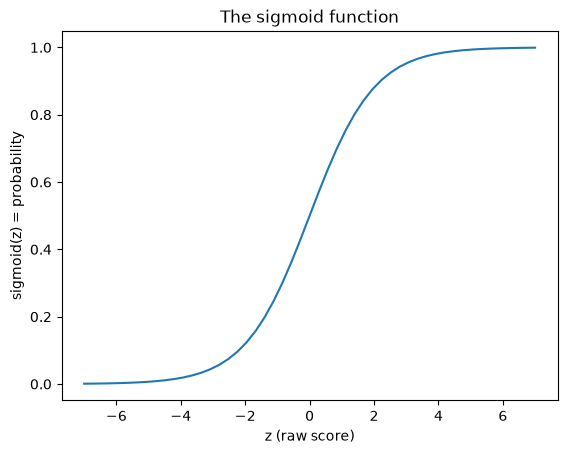

In [22]:
# Sigmoid: squashes any number into a probability in (0, 1)
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Plot the S-curve for intuition
z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))
plt.xlabel('z (raw score)')
plt.ylabel('sigmoid(z) = probability')
plt.title('The sigmoid function')
plt.show()


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Chain preprocessing + model
model = Pipeline([
    ('preprocess', preprocess),
    ('model', LogisticRegression(solver='lbfgs', max_iter=1000)),
])

# Fit on the training data
model.fit(df_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['limit_bal','sex','education',...,'pay_amt4','pay_amt5','pay_amt6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remai

## 3.10 Evaluate on the validation set

`.predict_proba(X)[:, 1]` gives the predicted probability of the positive class
(default) for every validation row. We threshold at 0.5 to get hard decisions, then
compute accuracy.

**Package:** `sklearn` (fitted pipeline).


In [24]:
# Predicted P(default) for each validation row
y_pred = model.predict_proba(df_val)[:, 1]

# 0.5 threshold -> 0/1, then accuracy
default_decision = (y_pred >= 0.5)
accuracy = (y_val == default_decision).mean()
accuracy


np.float64(0.8236666666666667)

## 3.11 Interpret the model: which features matter?

Each encoded feature gets a learned **weight**:

- **Positive** -> pushes toward default (the positive class).
- **Negative** -> pushes toward repaid.
- **Larger magnitude** -> stronger effect.

To label the weights we recover feature names in the encoder's order (categorical
one-hot names first, then numeric names).

**Package:** `sklearn` (fitted `Pipeline.named_steps`).


In [25]:
# Fitted one-hot encoder buried in the pipeline
encoder = model.named_steps['preprocess'].named_transformers_['cat']

# Feature names in the same order as the coefficients
feature_names = list(encoder.get_feature_names_out(categorical)) + numerical

# Pair names with weights, most positive first
coefs = pd.Series(model.named_steps['model'].coef_[0], index=feature_names)
coefs.sort_values(ascending=False).round(3)


pay_0_3        1.064
pay_0_2        0.998
pay_6_3        0.716
pay_4_4        0.625
education_2    0.480
               ...  
pay_5_4       -0.540
education_4   -0.857
marriage_0    -1.006
pay_0_-2      -1.042
pay_0_0       -1.232
Length: 90, dtype: float64

**Reading it:** the `pay_*` repayment-status codes (especially recent ones like
`pay_0`) carry the largest positive weights — customers who have been late are much
more likely to default. High `limit_bal` and older `age` tend to push *down* (negative
weights), i.e. more established customers default less.


## 3.12 Final model + evaluation on the test set

Refit on **train + validation** (more data), then evaluate **once** on the untouched
**test set**. That's our most honest estimate of real-world performance.

**Package:** `sklearn.pipeline.Pipeline`, `sklearn.linear_model.LogisticRegression`.


In [26]:
# Combine train + validation features and labels
X_full_train = df_full_train[categorical + numerical]

# Same architecture, refit on the larger dataset
model_full = Pipeline([
    ('preprocess', preprocess),
    ('model', LogisticRegression(solver='lbfgs', max_iter=1000)),
])
model_full.fit(X_full_train, y_full_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['sex','education','marriage',...,'pay_amt4','pay_amt5','pay_amt6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remain

In [27]:
# Predict probabilities on the untouched test set
y_pred_test = model_full.predict_proba(df_test[categorical + numerical])[:, 1]

# Turn probabilities into 0/1 decisions with the 0.5 cutoff,
# then compare them with the true labels: accuracy = share we got right.
test_decision = (y_pred_test >= 0.5)
test_accuracy = (test_decision == y_test).mean()
test_accuracy


np.float64(0.818)

## 3.13 Error analysis

In classification there are no numeric *residuals* (that's a regression idea); the
equivalent is **error analysis** — understanding where the model is wrong. We use
the **test set**.

**Packages:** `sklearn.metrics`, `pandas`, `matplotlib`.

### The confusion matrix

|                | predicted **no default** | predicted **default** |
|----------------|--------------------------|-----------------------|
| **actual no**  | True Negative (TN) ✓ | False Positive (FP) — "false alarm" |
| **actual yes** | False Negative (FN) — "missed default" | True Positive (TP) ✓ |

For a lender, a **false negative** (missing an eventual defaulter) is usually the
expensive mistake; a false positive just means declining a good customer.

**Package:** `sklearn.metrics.confusion_matrix`.


### Why we need more than one metric

A single "accuracy" number can hide a useless model. Example: in a dataset that's
**99% "no default"**, a model that *always* predicts "no default" scores 0.99 — while
catching **zero** defaulters. That's why this dataset (about **22% default / 78%
repaid**) is a perfect illustration: accuracy looks fine, but the model misses most
defaulters.

There is no single "best" metric. Each answers a different question. This section
builds the toolbox and explains **when** to reach for each one.


### The 2x2 confusion matrix: the source of everything

Every binary prediction lands in one of four boxes. Learn this table once and every
metric becomes a simple ratio of its cells.

| | predicted **no default** (0) | predicted **default** (1) |
|---|---|---|
| **actual no default** (0) | **TN** — correctly said no | **FP** — false alarm |
| **actual default** (1) | **FN** — missed default | **TP** — correctly flagged |

**True/False** = was the *prediction* right; **Positive/Negative** = *what we
predicted*. A **False Negative** is "we predicted repaid, but they defaulted."

**Why the split matters — error costs differ by domain:**

- **Lending / credit risk (this problem):** an **FN** (approving someone who
  defaults) can mean a big monetary loss; an **FP** (declining a customer who'd have
  repaid) means lost revenue and a possibly unhappy customer. Banks usually weight
  the FN more heavily.
- **Cancer screening:** an FN (missing a cancer) can be fatal; an FP is just an extra
  test. -> minimize FN.
- **Spam filtering:** an FP (real email in spam) is often worse than an FN (one spam
  in the inbox). -> minimize FP.

The confusion matrix forces us to *see* both error types before choosing a metric.


### The metric cheat-sheet (what each one answers)

| Metric | Question it answers | Formula | Use it when |
|---|---|---|---|
| **Accuracy** | Overall, how often are we right? | `(TP+TN) / all` | Classes balanced; all errors equal cost |
| **Precision** | When we say "default", how often right? | `TP / (TP+FP)` | False positives are expensive |
| **Recall** | Of real defaults, how many caught? | `TP / (TP+FN)` | False negatives are expensive (risk, fraud, churn) |
| **F1** | Balance precision & recall in one number | harmonic mean | Single number needed; both errors matter |
| **ROC-AUC** | How well does it *rank* positives above negatives (all thresholds)? | area under ROC | Comparing models before picking a cutoff |
| **PR-AUC** | Same, focused on the rare positive class | area under PR curve | Strongly imbalanced data |

We use the first five below, with this dataset's numbers (test set:
TN=4454, FP=209, FN=883, TP=454).


### Step 1: the confusion matrix — see the two error types

We compute the confusion matrix first because it shows the raw split of mistakes:
**false alarms** vs **missed defaults**.

**Use case here:** for a lender, an **FN** (approve a customer who then defaults)
is often the costliest error — it's real money lost. An **FP** (decline a customer
who would have repaid) costs the interest/fees we gave up plus possible
dissatisfaction. Which one you minimize depends on the bank's risk appetite; the FN
is usually weighted more heavily.

**Package:** `sklearn.metrics.confusion_matrix`.


In [28]:
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, precision_score, recall_score)

# Build the 2x2 count table of every possible outcome.
#   y_test        = the truth (defaulted or not?)
#   test_decision = the guess (0/1 after the 0.5 threshold)
#
#                   predicted 0              predicted 1
#   actual 0        TN (correct)             FP (false alarm)
#   actual 1        FN (missed defaulter)    TP (correct)
cm = confusion_matrix(y_test, test_decision)
print(cm)          # raw grid: row 0 = actual 0, row 1 = actual 1

# .ravel() flattens that grid into 4 numbers in READING ORDER:
#   TN (top-left), FP (top-right), FN (bottom-left), TP (bottom-right)
tn, fp, fn, tp = cm.ravel()

# Read the four boxes out loud, e.g.:
#   "of the actual defaulters we caught TP and missed FN".
# The total MUST equal the number of test rows. If it doesn't, the target has
# more than 2 values and the matrix is not 2x2.
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
print(f'sanity check -> {tn} + {fp} + {fn} + {tp} = {tn + fp + fn + tp}'
      f'  (test rows = {len(y_test)})')


[[4454  209]
 [ 883  454]]
TN=4454  FP=209  FN=883  TP=454
sanity check -> 4454 + 209 + 883 + 454 = 6000  (test rows = 6000)


### Step 2: accuracy, precision, recall, F1, ROC-AUC

All the "yes" metrics here are computed for the **positive** class (default). With
this test set (TN=4454, FP=209, FN=883, TP=454):

**Accuracy** = `(TP + TN) / everything`
> "Fraction of all predictions that were correct." Intuitive but **misleading on
> imbalanced data**: defaulters are only ~22%, so always predicting "no default"
> already scores ~0.78. Our accuracy (~0.82) barely beats that — a first warning
> sign. **Always compare accuracy to the majority-class baseline.**

**Precision** = `TP / (TP + FP)`
> "When we flag a default, how often is it real?" High precision = few **false
> alarms** (declining good customers). Use it when a false positive is expensive.
> Here precision ≈ 0.69.

**Recall** (sensitivity) = `TP / (TP + FN)`
> "Of the real defaulters, how many did we catch?" High recall = few **misses**. Use
> it when a false negative is expensive — **exactly this problem**: a missed
> defaulter is money lost. Here recall ≈ **0.34** — we catch only about a third.
> That's the headline weakness.

**F1** = harmonic mean of precision and recall
> A single number balancing both; high only when both are decent. Useful when both
> error types matter and the negative class is huge. Here F1 ≈ 0.45 — modest.

**ROC-AUC** = area under the ROC curve, over every threshold
> "Given a random defaulter and a random non-defaulter, how often does the model score
> the defaulter higher?" Threshold-free; measures **ranking** quality. 0.5 = random,
> 1.0 = perfect. Here ≈ **0.77** — better than chance, but not strong. Great for
> **comparing candidate models** before you commit to a cutoff.

**The golden rule:** precision and recall trade off via the threshold (Step 3).
ROC-AUC summarizes the model *before* that choice; precision/recall describe it
*after*.

**Package:** `sklearn.metrics` (`classification_report`, `roc_auc_score`).


In [29]:
# Precision, recall, F1 per class + overall accuracy.
# Read the report top-down:
#   'precision' = when we predict this class, how often are we right?
#   'recall'    = of the rows that truly are this class, how many did we catch?
#   'support'   = how many true examples of this class exist in the test set
#   'macro avg' = plain average of the two classes (each class weighs the same)
#   'weighted avg' = average weighted by support (= dominated by the big class)
# Look at the row for class 1 (default): that is the class we care about.
print(classification_report(y_test, test_decision, digits=3))

# ROC-AUC: ranking quality over ALL thresholds (uses the raw probabilities,
# not the 0/1 decisions). 0.5 = coin flip, 1.0 = perfect.
print('ROC-AUC :', round(roc_auc_score(y_test, y_pred_test), 3))

# Baseline: accuracy if we always guessed "no default" (0) = share of non-defaulters.
# Our accuracy is only meaningful if it clearly beats this number.
print('Baseline (always 0):', round((y_test == 0).mean(), 3))


              precision    recall  f1-score   support

           0      0.835     0.955     0.891      4663
           1      0.685     0.340     0.454      1337

    accuracy                          0.818      6000
   macro avg      0.760     0.647     0.672      6000
weighted avg      0.801     0.818     0.793      6000

ROC-AUC : 0.77
Baseline (always 0): 0.777


**Reading it:** test accuracy (~0.82) barely beats the ~0.78 baseline, and the
class-1 (default) row shows **recall around 34%** — we catch only about a third of
real defaulters. Precision (~0.68) and ROC-AUC (~0.77) confirm the model is better
than chance but far from strong. This is exactly why **accuracy alone is
dangerous** on imbalanced data.


### Step 3: moving the threshold — the precision/recall dial

The model outputs a **probability**; the 0.5 cutoff is just a default. Moving it
trades the two errors against each other:

- **Lower** the threshold -> flag more customers as risky -> **recall up, precision
  down** (catch more defaulters, more false alarms).
- **Raise** it -> flag only the most confident -> **precision up, recall down**
  (fewer false alarms, but more missed defaults).

**Use case (how a lender chooses):** pick the threshold from the **cost** of each
error. If a default costs the bank far more than a declined good customer, lower the
threshold to buy recall. A rough rule: flag default when
`P(default) > cost_of_declining / loss_from_default`. You can also target a fixed
recall (e.g. "catch at least 70% of defaulters") and accept the resulting precision.


In [30]:
# Precision & recall at several thresholds.
#   d = the 0/1 decision we *would* make if the cutoff were t
#   Lower t  -> more customers flagged as risky -> recall up, precision down
#   Higher t -> fewer customers flagged -> precision up, recall down
# zero_division=0 avoids a warning when nothing is predicted positive at all.
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    d = (y_pred_test >= t).astype(int)
    p = precision_score(y_test, d, zero_division=0)
    r = recall_score(y_test, d, zero_division=0)
    print(f'threshold={t}:  precision={p:.3f}  recall={r:.3f}')


threshold=0.3:  precision=0.583  recall=0.476
threshold=0.4:  precision=0.662  recall=0.388
threshold=0.5:  precision=0.685  recall=0.340
threshold=0.6:  precision=0.715  recall=0.271
threshold=0.7:  precision=0.750  recall=0.164


### Step 4: the predicted-probability distribution (calibration view)

Plot the predicted probability separately for the two true classes.

A **well-separated** model piles non-defaulters near 0 and defaulters near 1. Here
you'll see **large overlap** — most real defaulters get low predicted probabilities,
which is precisely *why* recall is low. This model simply isn't confident about who
will default.

**Why this view matters:**
- Separates **fixable** error (better features/model could push the humps apart) from
  **irreducible** error (the unavoidable overlap).
- Shows **calibration**: if the model says 0.8, is it right ~80% of the time? In
  credit risk, the *probability* itself drives expected-loss math, so calibration is
  as important as the yes/no decision.
- Makes the low recall **visual**: the positives sit under the threshold, not because
  the cutoff is wrong, but because the model can't tell them apart yet.


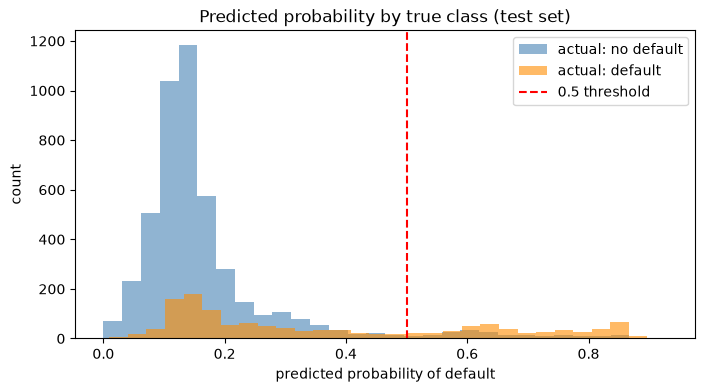

In [31]:
# Two histograms on the same axis, one per TRUE class:
#   blue   = predicted probability of customers who really did NOT default
#   orange = predicted probability of customers who really DID default
# A good model puts the two humps far apart; the overlap is where errors live.
plt.figure(figsize=(8, 4))
plt.hist(y_pred_test[y_test == 0], bins=30, alpha=0.6, label='actual: no default', color='steelblue')
plt.hist(y_pred_test[y_test == 1], bins=30, alpha=0.6, label='actual: default', color='darkorange')
# The 0.5 cutoff we used to turn probabilities into decisions
plt.axvline(0.5, color='red', linestyle='--', label='0.5 threshold')
plt.xlabel('predicted probability of default')
plt.ylabel('count')
plt.title('Predicted probability by true class (test set)')
plt.legend()
plt.show()


### Step 5: a dummy baseline — the sanity check every model needs

Before trusting any score, ask: **how good is a model that learns nothing?** A
`DummyClassifier` that always predicts the **most frequent class** ("no default")
scores exactly the non-default rate. Our real model must clearly beat it to be worth
anything.

**Why this matters here especially:** this dataset is imbalanced (~22% default), so
accuracy flatters lazy models. The dummy is the floor we must clear.

**Package:** `sklearn.dummy.DummyClassifier`.


In [32]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# DummyClassifier(strategy='most_frequent') always predicts the most common
# class in the training data - here "no default". It learns nothing at all.
dummy = DummyClassifier(strategy='most_frequent').fit(
    df_full_train[categorical + numerical], y_full_train)
dummy_acc = accuracy_score(y_test, dummy.predict(df_test[categorical + numerical]))

# The gap between the two is the value our real model actually adds.
print(f'dummy (always no default) accuracy: {dummy_acc:.3f}')
print(f'our model                accuracy: {test_accuracy:.3f}')
print(f'improvement                      : {test_accuracy - dummy_acc:+.3f}')


dummy (always no default) accuracy: 0.777
our model                accuracy: 0.818
improvement                      : +0.041


The dummy scores ~0.78 (the non-default rate); our model ~0.82 — a **real but small**
gain of about +0.04. Contrast that with recall (~0.34): we miss two-thirds of
defaulters. The dummy keeps us honest: "beats the baseline" is necessary, not
sufficient.

### Step 6: the ROC curve — seeing every threshold at once

ROC-AUC gave us one number; the **ROC curve** is the picture behind it. Sweep the
threshold from 0 to 1 and, at each setting, plot:

- **x-axis = False Positive Rate (FPR)** = `FP / (FP + TN)` — share of good customers
  we wrongly flagged.
- **y-axis = True Positive Rate (TPR)** = `TP / (TP + FN)` = **recall** — share of
  defaulters we caught.

The curve traces the **recall vs false-alarm trade-off** across *all* thresholds:

- The **diagonal** (TPR = FPR) is the **random** model.
- The **top-left corner** (TPR = 1, FPR = 0) is the **ideal** model.
- A good model bows toward the top-left; **AUC** is the area under it (0.5 diagonal,
  1.0 ideal).

**Package:** `sklearn.metrics.roc_curve`.


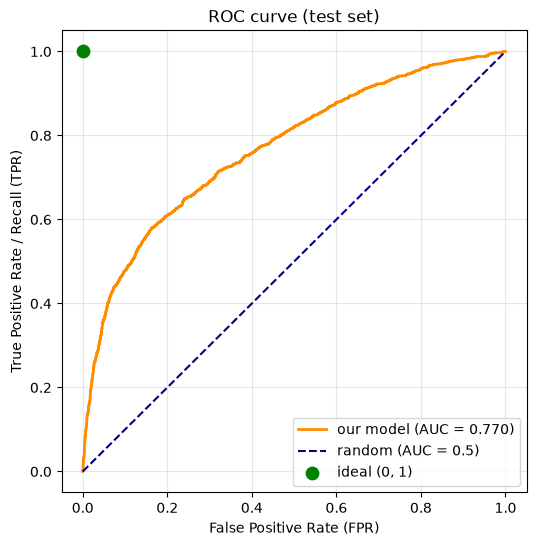

In [33]:
from sklearn.metrics import roc_curve

# Sweep the threshold from 0 to 1 and record, at each step:
#   fpr = share of good customers wrongly flagged (false alarms)
#   tpr = share of defaulters correctly caught (= recall)
# thresholds is returned too but we don't need it for the plot.
fpr, tpr, thresholds = roc_curve(y_test, y_pred_test)
# AUC = the single number: area under this curve
auc = roc_auc_score(y_test, y_pred_test)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'our model (AUC = {auc:.3f})')
# The diagonal y = x is a model that guesses at random
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='random (AUC = 0.5)')
# The perfect model: catches everything (TPR=1), flags nothing wrongly (FPR=0)
plt.scatter([0], [1], color='green', s=80, zorder=5, label='ideal (0, 1)')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate / Recall (TPR)')
plt.title('ROC curve (test set)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


The curve sits clearly above the diagonal (AUC ≈ 0.77) — the model **ranks**
defaulters above non-defaulters better than chance — but it's not close to the ideal
corner. That's the visual version of the low recall we saw at threshold 0.5: to catch
most defaulters you'd have to accept a lot of false alarms (move high up the y-axis →
FPR rises fast).

## 3.14 Cross-validation: a more reliable way to measure quality

Every number so far came from a **single** train/validation/test split — which
depends partly on **luck of the split**. Re-split and accuracy can shift by a point or
two. When comparing models or tuning settings, one split can mislead you.

**Cross-validation (k-fold)** fixes this:

1. Split the data into **k equal folds** (we use k = 5).
2. Train on k-1 folds, evaluate on the held-out fold; rotate so **each fold is the
   test set once**.
3. Report the **mean** of the k scores (the estimate) and their **std** (stability).

- **`StratifiedKFold`** keeps the class ratio in every fold — essential for imbalanced
  data, so no fold is nearly all one class.
- **`cross_val_score`** runs the whole loop for you, refitting the full pipeline
  (preprocessing included) on each fold — no leakage.

We run CV on **train + validation** (`df_full_train`); the test set still stays
untouched for the final check.

**Packages:** `sklearn.model_selection` (`StratifiedKFold`, `cross_val_score`).


In [34]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

# 5 stratified folds, shuffled (random_state makes it reproducible).
# 'stratified' = every fold keeps the same default / no-default ratio.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

# Features + target for CV: train + validation (the test set stays untouched)
X_all = df_full_train[categorical + numerical]
y_all = df_full_train[TARGET].values

# cross_val_score fits the whole pipeline once per fold and scores the
# held-out fold -> we get 5 numbers, one per fold.
cv_auc = cross_val_score(model_full, X_all, y_all, cv=cv, scoring='roc_auc')
print('AUC per fold:', [round(s, 3) for s in cv_auc])
# mean = our best estimate of quality; std = how much the score moves between folds
print(f'mean AUC: {cv_auc.mean():.3f}  (+/- {cv_auc.std():.3f})')


AUC per fold: [np.float64(0.774), np.float64(0.76), np.float64(0.779), np.float64(0.777), np.float64(0.75)]
mean AUC: 0.768  (+/- 0.011)


In [35]:
# Same loop, but scoring plain accuracy, to compare with the single-split number
cv_acc = cross_val_score(model_full, X_all, y_all, cv=cv, scoring='accuracy')
print('accuracy per fold:', [round(s, 3) for s in cv_acc])
print(f'mean accuracy: {cv_acc.mean():.3f}  (+/- {cv_acc.std():.3f})')


accuracy per fold: [np.float64(0.819), np.float64(0.825), np.float64(0.826), np.float64(0.822), np.float64(0.813)]
mean accuracy: 0.821  (+/- 0.005)


The folds cluster tightly (mean AUC ≈ 0.77 ± 0.011), so the single-split test AUC of
0.77 was a fair, stable estimate — the result is not a fluke of one split.

### Tuning parameters with cross-validation

Now the payoff: **choosing hyperparameters**. Logistic regression has a
regularization strength `C` (small `C` = more regularization). Instead of guessing, try
several values and let **`GridSearchCV`** run k-fold CV for each, keeping the best by
**mean CV score** — never by the test set.

**Package:** `sklearn.model_selection.GridSearchCV`.



In [36]:
from sklearn.model_selection import GridSearchCV

# Try each C value and score it with the same 5-fold CV used above.
# NOTE: in a Pipeline you must prefix the parameter with the step name,
# so the model's C is addressed as 'model__C' (step name + '__' + param).
param_grid = {'model__C': [0.001, 0.01, 0.1, 1, 10]}

# GridSearchCV = "try every combination, keep the one with the best mean CV score".
# n_jobs=-1 = use all CPU cores (faster).
grid = GridSearchCV(model_full, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_all, y_all)

print('best C      :', grid.best_params_['model__C'])
print('best CV AUC :', round(grid.best_score_, 3))


best C      : 0.01
best CV AUC : 0.768


The best `C` barely moves CV AUC — a useful finding: **tuning `C` won't rescue this
model.** The real wins here come from handling imbalance (`class_weight`), better
features, or a stronger model (see Next steps).


## 3.15 Summary

**Workflow:** load & clean -> split (60/20/20) -> profile -> rank features ->
one-hot + scale in a `Pipeline` -> fit `LogisticRegression` -> read coefficients ->
refit on train+val -> evaluate on test -> error analysis.

**Results on this dataset (test set):**
- Accuracy ~0.82 vs a ~0.78 majority-class baseline — only a small gain.
- Defaulter **recall ~0.34**, precision ~0.68, ROC-AUC ~0.77.
- Confusion matrix: **TN=4454, FP=209, FN=883, TP=454**.

**Key concepts**
- **Feature importance** — risk ratio / mutual information / correlation.
- **One-hot encoding** — categories (even integer-coded ones) -> 0/1 columns.
- **Logistic regression** — linear model + sigmoid -> probability.
- **Imbalanced data** — accuracy misleads; rely on precision/recall/F1 and ROC-AUC.
- **Threshold choice** — trade false alarms against missed positives.

**Reusing the template:** the knobs changed were `DATA_PATH`, `TARGET`,
`POSITIVE_LABEL`, `numerical`, `categorical` — nothing else.

## 3.16 Next steps

- **Fix the imbalance problem** — try `class_weight='balanced'` in
  `LogisticRegression`, or resampling (SMOTE/undersampling).
- **Improve the model** — tree models (`RandomForestClassifier`,
  `GradientBoostingClassifier`) often handle this data much better; compare ROC-AUC.
- **Feature engineering** — ratios like `bill_amt / limit_bal` or "months late"
  counts from the `pay_*` columns.
- **Pick a threshold by cost** — choose based on the dollar cost of a missed default
  vs a declined good customer.

